<a href="https://colab.research.google.com/github/vzavala/DesignOfExperiments/blob/main/Python/BoxBehnkenvsArbitraryDesign.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Setup.** Run this cell first: it locates the data files this notebook reads. On Google
Colab it downloads them (the `Data/` and `Support/` folders) from the book's GitHub
repository; on your computer, run the notebook from the folder that contains `Data/`.

In [1]:
import os
import sys
path = ''
if 'google.colab' in sys.modules and not os.path.isdir('Data'):
    if not os.path.isdir('statsbook'):
        os.system('git clone -q --depth 1 --filter=blob:none --sparse '
                  'https://github.com/vzavala/DesignOfExperiments.git statsbook')
        os.system('git -C statsbook sparse-checkout set Python/Data Python/Support')
    path = 'statsbook/Python/'

Box-Behnken against an arbitrary design with the same number of experiments (Victor Z, UW-Madison, 2026).

| Slides | Python | Meaning |
|---|---|---|
| $\mathbf{X}$ (Box-Behnken), $\mathbf{X}$ (arbitrary) | `X_bb`, `X_arb` | design matrices (17 experiments each) |
| $\mathcal{I}=\mathbf{X}^T\mathbf{X}$ | `FI_bb`, `FI_arb` | Fisher information |
| $\hat{\sigma}$ | `sigma_hat` | noise SD (estimated from the Box-Behnken data) |
| $\mathrm{SD}[\hat{\theta}]$ | `SD_bb`, `SD_arb` | parameter standard errors |

**Note:** This notebook compares the Box-Behnken design of the slides with 17 experiments placed at random in the same space, for the same model and the same noise.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def features(x):
    """Row(s) of the design matrix for the quadratic model."""
    x1, x2, x3 = np.atleast_2d(x).T
    return np.column_stack([np.ones(len(x1)), x1, x2, x3, x1**2, x2**2, x3**2, x1*x2, x1*x3, x2*x3])

D = np.loadtxt(path + "Data/box_behnken.dat")
X_bb, y = features(D[:, :3]), D[:, 3]
S = len(y)

np.random.seed(42)
x_arb = np.random.uniform(-1, 1, size=(S, 3))    # 17 arbitrary experiments in [-1, 1]^3
X_arb = features(x_arb)

Fisher information of each design. The total information can be measured with the determinant
(product of the eigenvalues).

eigenvalues, Box-Behnken: [ 2.63  4.    4.    4.    4.    4.    8.    8.    8.   30.37]
eigenvalues, arbitrary:   [ 0.19  0.49  0.6   1.05  1.6   2.85  5.02  6.81  8.78 24.55]
det(I): Box-Behnken 4.19e+07, arbitrary 1.96e+03


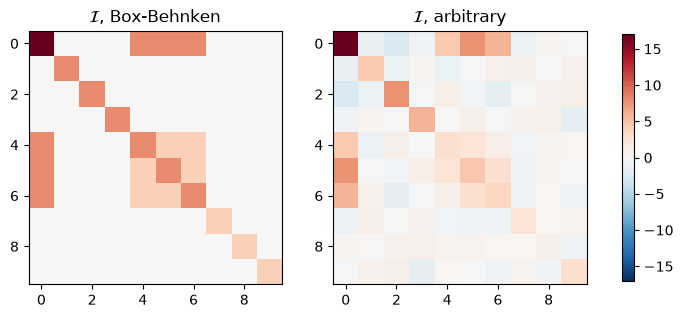

In [3]:
FI_bb, FI_arb = X_bb.T @ X_bb, X_arb.T @ X_arb
print("eigenvalues, Box-Behnken:", np.round(np.linalg.eigvalsh(FI_bb), 2))
print("eigenvalues, arbitrary:  ", np.round(np.linalg.eigvalsh(FI_arb), 2))
print(f"det(I): Box-Behnken {np.linalg.det(FI_bb):.2e}, arbitrary {np.linalg.det(FI_arb):.2e}")

fig, axs = plt.subplots(1, 2, figsize=(9, 4))
for ax, F, t in zip(axs, (FI_bb, FI_arb), ("Box-Behnken", "arbitrary")):
    im = ax.imshow(F, cmap="RdBu_r", vmin=-17, vmax=17)
    ax.set_title(r"$\mathcal{I}$, " + t)
fig.colorbar(im, ax=axs, shrink=0.8)
plt.show()

Standard errors $\mathrm{SD}[\hat{\theta}]=\sqrt{\mathrm{diag}(\hat{\sigma}^2\mathcal{I}^{-1})}$, with the same $\hat{\sigma}$ for both designs.

   term  SD Box-Behnken  SD arbitrary  increase [%]
0     1           0.110         0.190        72.640
1    X1           0.087         0.173        98.666
2    X2           0.087         0.119        36.587
3    X3           0.087         0.156        79.695
4  X1^2           0.120         0.287       139.738
5  X2^2           0.120         0.333       177.736
6  X3^2           0.120         0.268       123.233
7  X1X2           0.123         0.240        94.771
8  X1X3           0.123         0.432       251.493
9  X2X3           0.123         0.272       120.818


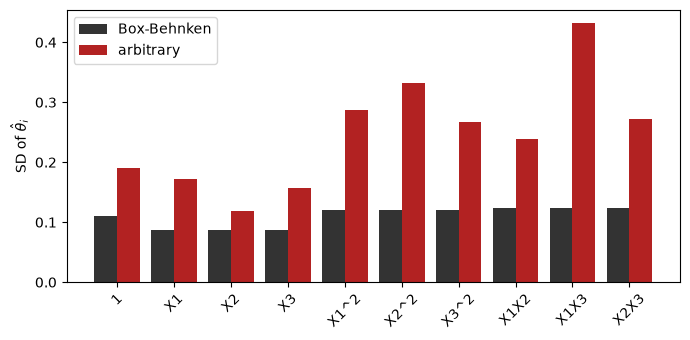

In [4]:
theta_hat = np.linalg.solve(FI_bb, X_bb.T @ y)
eps_hat = y - X_bb @ theta_hat
sigma_hat = np.sqrt(eps_hat @ eps_hat / (S - 10))
SD_bb = sigma_hat * np.sqrt(np.diag(np.linalg.inv(FI_bb)))
SD_arb = sigma_hat * np.sqrt(np.diag(np.linalg.inv(FI_arb)))
terms = ["1", "X1", "X2", "X3", "X1^2", "X2^2", "X3^2", "X1X2", "X1X3", "X2X3"]
print(pd.DataFrame({"term": terms, "SD Box-Behnken": SD_bb, "SD arbitrary": SD_arb,
                    "increase [%]": 100 * (SD_arb / SD_bb - 1)}).round(3).to_string())

i = np.arange(10)
plt.figure(figsize=(7, 3.5))
plt.bar(i - 0.2, SD_bb, 0.4, label="Box-Behnken", color="0.2")
plt.bar(i + 0.2, SD_arb, 0.4, label="arbitrary", color="firebrick")
plt.xticks(i, terms, rotation=45); plt.ylabel(r"SD of $\hat{\theta}_i$"); plt.legend()
plt.tight_layout(); plt.show()

**Note:** With the same number of experiments, the arbitrary design has much less information (smaller determinant and smallest eigenvalue, correlated parameters) and gives larger standard errors, especially for the quadratic and interaction terms.